<a href="https://colab.research.google.com/github/V-Varaniya/IT5022-Group-ML-Assignment/blob/feature%2Flogiregresssion-random-forest/ML_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Logistic Regression ===
              precision    recall  f1-score   support

      notckd       1.00      1.00      1.00        14
         ckd       1.00      1.00      1.00        26

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

ROC-AUC: 1.0


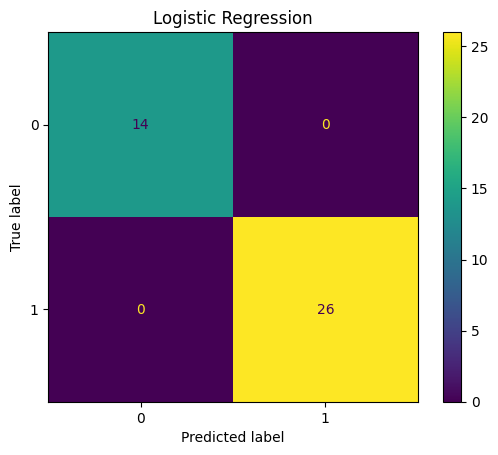

=== Random Forest ===
              precision    recall  f1-score   support

      notckd       1.00      1.00      1.00        14
         ckd       1.00      1.00      1.00        26

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

ROC-AUC: 1.0


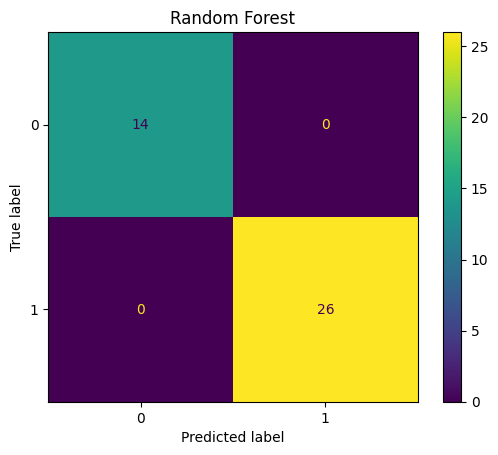

Logistic Regression {'test_accuracy': np.float64(0.98), 'test_precision': np.float64(0.993), 'test_recall': np.float64(0.977), 'test_f1': np.float64(0.984)}
Random Forest {'test_accuracy': np.float64(0.995), 'test_precision': np.float64(0.992), 'test_recall': np.float64(1.0), 'test_f1': np.float64(0.996)}


In [ ]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

# 1. Load (skip the 2 extra header rows)
df = pd.read_csv("/content/drive/MyDrive/ML Assignment/ckd-dataset-v2.csv", skiprows=[1, 2])

# 2. Drop leaky columns
df = df.drop(columns=["affected", "stage", "grf"])

# 3. Convert bins like "1.019 - 1.021", "< 112", "≥ 448" to numbers
def bin_to_num(v):
    nums = [float(x) for x in re.findall(r"\d+\.?\d*", str(v))]
    return np.mean(nums) if nums else np.nan

for col in df.columns:
    if col == "class":
        continue
    if df[col].dtype == object or str(df[col].dtype).startswith("str"):
        df[col] = df[col].apply(bin_to_num)

X = df.drop(columns=["class"])
y = (df["class"] == "ckd").astype(int)

# 4. Train/test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 5. Two models
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["notckd", "ckd"]))
    print("ROC-AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
    plt.title(name); plt.show()

# 6. Cross-validation (more reliable with 200 rows)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    print(name, {k: round(v.mean(), 3) for k, v in s.items() if k.startswith("test")})